# Figure 3: Mentioning without citing

Rebuild the comparison between papers that mention an open-source package and papers that cite its own papers, for the nine packages whose papers Europe PMC indexes.

## Inputs

| Committed file | Contents | Producer |
| --- | --- | --- |
| `config/tools.yml` | Curated aliases, categories and query context | Manual registry, read by `python -m census.build.build_dataset` |
| `data/processed/tools.csv` | Package names, categories, scope and aggregate flags | `python -m census.build.build_dataset` |
| `data/processed/mentions_citations_yearly.csv` | Yearly mentioned, cited and overlapping paper counts | `python -m census.build.build_citations` |
| `config/package_papers.yml` | Curated DOI list for citation-query construction | Manual bibliography, read by `python -m census.build.build_citations` |
| `notebooks/data/citation_reference_metadata.json` | Indexed reference identifiers and earliest publication years, with no article text | Export of `census.build.build_citations.own_papers()` and `first_paper_year()` using the saved responses from `python -m census.build.build_citations` |

Input paths are relative to the repository root. The closing check also reads `../MANUSCRIPT/FIGURES/Figure3__citations.png` when present. The manuscript image is optional and stays outside a public clone.

## Set up offline analysis

Locate the repository in either layout, load the package registry and import the shared publication renderer. This cell makes no API requests.

In [1]:
from pathlib import Path
from io import BytesIO
from tempfile import TemporaryDirectory
import sys
import hashlib

import numpy as np
import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
SCRIPTS_DIR = next(p for p in (cwd, *cwd.parents) if (p / 'census' / '_registry.py').is_file())
REPO_ROOT = SCRIPTS_DIR.parent
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import fig3_citations as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame


## Citation queries for panels a-b

Construct mention and citation queries from the curated DOI list and committed indexed identifiers. The earliest publication years restrict panel b to eligible years, this cell reads the saved metadata without an API lookup.

In [2]:
import json
from census.build import build_citations as bc
metadata = json.loads((SCRIPTS_DIR / 'notebooks/data/citation_reference_metadata.json').read_text())
first_years = metadata['first_years']
own = metadata['own_papers']
jobs = bc.build_queries(reg, own)
for key in [('qupath', 2025, k) for k in ('named', 'cited', 'both')]:
    print(key, jobs[key])
print('Earliest indexed reference years:', first_years)


('qupath', 2025, 'named') QuPath* AND ((microscopy OR microscope) AND HAS_FT:Y) AND PUB_YEAR:2025
('qupath', 2025, 'cited') (CITES:29203879_MED) AND ((microscopy OR microscope) AND HAS_FT:Y) AND PUB_YEAR:2025
('qupath', 2025, 'both') QuPath* AND ((microscopy OR microscope) AND HAS_FT:Y) AND (CITES:29203879_MED) AND PUB_YEAR:2025
Earliest indexed reference years: {'imagej': 2012, 'qupath': 2017, 'cellprofiler': 2006, 'ilastik': 2019, 'icy': 2012, 'cellpose': 2021, 'deepimagej': 2021, 'zerocostdl4mic': 2021, 'skimage': 2014}


## Read panel inputs

Load the committed data for the calculations below. Panel a partitions papers into mentioned only, cited only and both. Panel b compares the mention-without-citation share in the first eligible year from 2020 with 2025.

In [3]:
inspect_processed('mentions_citations_yearly.csv')

mentions_citations_yearly.csv: shape=(224, 8)


,tool_id,method,year,named,cited,both,named_not_cited,cited_not_named
0,imagej,links,2010,4314,0,0,4314,0
1,imagej,links,2011,5957,0,0,5957,0
2,imagej,links,2012,7781,39,39,7742,0
3,imagej,links,2013,9824,422,382,9442,40
4,imagej,links,2014,11405,848,789,10616,59


,tool_id,method,year,named,cited,both,named_not_cited,cited_not_named
0,imagej,links,2010,4314,0,0,4314,0
1,imagej,links,2011,5957,0,0,5957,0
2,imagej,links,2012,7781,39,39,7742,0
3,imagej,links,2013,9824,422,382,9442,40
4,imagej,links,2014,11405,848,789,10616,59
...,...,...,...,...,...,...,...,...
219,opencv,titles,2021,220,68,57,163,11
220,opencv,titles,2022,302,121,99,203,22
221,opencv,titles,2023,290,109,87,203,22
222,opencv,titles,2024,341,91,73,268,18


## Reconstruct panel quantities

Panel a partitions papers into mentioned only, cited only and both. Panel b compares the mention-without-citation share in the first eligible year from 2020 with 2025.

In [4]:
table = figure.table()
display(figure.union(table).round(1))
display(figure.yearly(first_years=first_years).pivot(index='year', columns='tool_id', values='share').round(0))
union = figure.union(table)
change = figure.change(first_years=first_years)
yearly = figure.yearly(first_years=first_years).set_index(['tool_id', 'year'])['share']
assert set(change.index) <= set(union.index)
for tool_id, row in change.iterrows():
    first = min(year for year in yearly.loc[tool_id].index if 2020 <= year < 2025)
    assert first == int(row.start_year), (tool_id, first, int(row.start_year))
    np.testing.assert_allclose([yearly.loc[(tool_id, int(row.start_year))], yearly.loc[(tool_id, 2025)]],
                               [row.start, row.end], rtol=1e-12)
assert set(union.index) - set(change.index) == {'deepimagej'}
display(change.assign(start_year=change.start_year.astype(int)).round(1))
print(f'Panel b covers {len(change)} of the {len(union)} packages; Cellpose and ZCDL4M/DL4ME start in 2022 and deepImageJ has fewer than 20 mentioning papers a year.')


,label,no,both,co,total,no_pct,both_pct,co_pct
tool_id,,,,,,,,
cellpose,Cellpose,350,1475,211,2036,17.2,72.4,10.4
cellprofiler,CellProfiler,2419,2098,319,4836,50.0,43.4,6.6
deepimagej,deepImageJ,17,56,48,121,14.0,46.3,39.7
icy,Icy,198,129,238,565,35.0,22.8,42.1
ilastik,ilastik,514,1029,136,1679,30.6,61.3,8.1
imagej,ImageJ/Fiji,176887,26527,1550,204964,86.3,12.9,0.8
qupath,QuPath,2308,2459,67,4834,47.7,50.9,1.4
skimage,scikit-image,765,594,229,1588,48.2,37.4,14.4
zerocostdl4mic,ZCDL4M/DL4ME,21,112,93,226,9.3,49.6,41.2


tool_id,cellpose,cellprofiler,icy,ilastik,imagej,qupath,skimage,zerocostdl4mic
year,,,,,,,,
2010,NaN,25.0,NaN,NaN,NaN,NaN,NaN,NaN
2011,NaN,30.0,NaN,NaN,NaN,NaN,NaN,NaN
2012,NaN,40.0,NaN,NaN,NaN,NaN,NaN,NaN
2013,NaN,43.0,NaN,NaN,96.0,NaN,NaN,NaN
2014,NaN,49.0,NaN,NaN,93.0,NaN,NaN,NaN
2015,NaN,51.0,NaN,NaN,91.0,NaN,NaN,NaN
2016,NaN,54.0,44.0,NaN,90.0,NaN,NaN,NaN
2017,NaN,53.0,24.0,NaN,88.0,NaN,50.0,NaN
2018,NaN,52.0,36.0,NaN,88.0,NaN,38.0,NaN


,start_year,start,end
tool_id,,,
cellpose,2022,11.7,20.9
cellprofiler,2020,53.9,50.5
icy,2020,35.1,39.8
ilastik,2020,50.6,27.4
imagej,2020,86.0,87.7
qupath,2020,32.0,52.1
skimage,2020,43.6,52.3
zerocostdl4mic,2022,6.0,10.3


Panel b covers 8 of the 9 packages; Cellpose and ZCDL4M/DL4ME start in 2022 and deepImageJ has fewer than 20 mentioning papers a year.


## Rebuilding from scratch

All default cells run offline from the committed inputs above. Source collectors need network access when their raw API caches are absent. `python -m census.build.build_dataset` collects counts and snapshots, the specialised producer modules listed under Inputs rebuild their own derived tables. Snapshots retain their original collection date.

To restore sampled titles and abstracts, run `python release/refetch_identifiers.py` with network access. The refetched corpus supports vocabulary classification and research-area calculations. A public clone omits that corpus and the raw response caches. These notebooks display derived data and never fetch records during execution.

`python -m census.build.build_citations` resolves the curated DOI list through Europe PMC. Export `own_papers()` and `first_paper_year()` as the two JSON keys in `notebooks/data/citation_reference_metadata.json`. Those saved identifiers and years keep query construction and panel b offline.

## Render all panels

Build `Figure3__citations` with the shared 300 dpi publication style. Save PNG, PDF and SVG in a temporary directory and retain the full-size PNG pixels for the closing check. Display a scaled preview.

wrote Figure3__citations.png/.pdf/.svg
Figure3__citations: 1885 x 1221 pixels


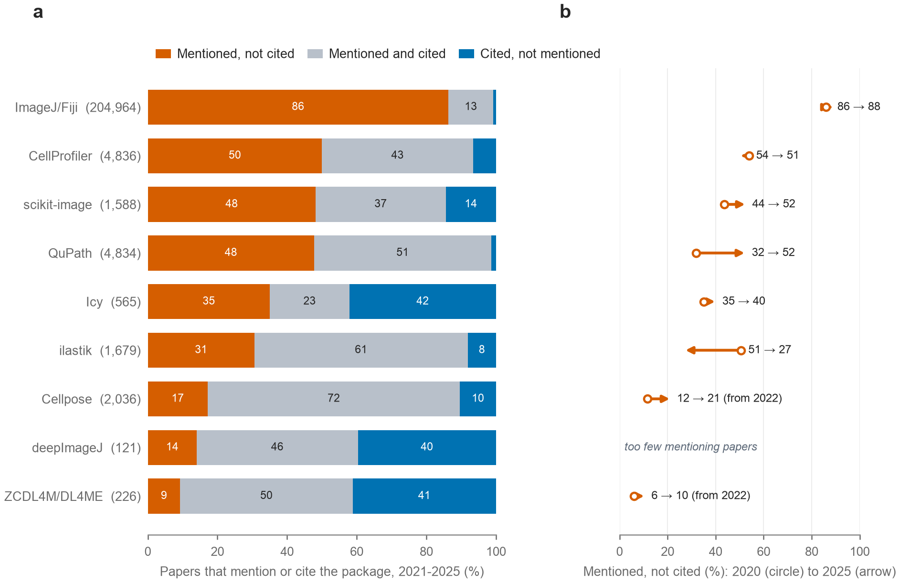

In [5]:
OUTPUT_STEM = 'Figure3__citations'
fig = figure.build_figure(first_years=first_years)
with TemporaryDirectory(prefix='notebook-render-') as output_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=output_dir)
    png_bytes = (Path(output_dir) / (OUTPUT_STEM + '.png')).read_bytes()
rendered_pixels = np.asarray(PILImage.open(BytesIO(png_bytes)).convert('RGBA'))
print(f'{OUTPUT_STEM}: {rendered_pixels.shape[1]} x {rendered_pixels.shape[0]} pixels')
preview = PILImage.open(BytesIO(png_bytes))
preview.thumbnail((900, 900))
preview_bytes = BytesIO()
preview.save(preview_bytes, format='PNG')
display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')


## Historical variant

`Figure3_new_DL_in_tools` is an earlier deep-learning estimator figure in the manuscript working folder. The current paper cites `Figure3__citations`. This notebook reproduces the current citation figure, the historical PNG is outside the publication targets.

## Check against the manuscript

Assert exact pixel equality, including image dimensions and every panel, when the manuscript PNG exists. A public clone prints a skip note for that comparison and still checks that rendering produced pixels. The pixel hash supports comparisons across runs.

In [6]:
assert rendered_pixels.size > 0
reference = REPO_ROOT / 'MANUSCRIPT' / 'FIGURES' / (OUTPUT_STEM + '.png')
if reference.is_file():
    expected_pixels = np.asarray(PILImage.open(reference).convert('RGBA'))
    assert rendered_pixels.shape == expected_pixels.shape, 'Manuscript image dimensions differ'
    np.testing.assert_array_equal(rendered_pixels, expected_pixels)
    print(f'{OUTPUT_STEM}: identical to manuscript PNG (all pixels, all panels)')
else:
    print(f'{OUTPUT_STEM}: manuscript comparison skipped; manuscript PNG is absent in this clone')
print('Rendered pixel SHA-256:', hashlib.sha256(rendered_pixels.tobytes()).hexdigest())


Figure3__citations: identical to manuscript PNG (all pixels, all panels)
Rendered pixel SHA-256: b13e9bd55a4d1ebc12cec3b8e1a4f30e76376cd37b3c01f44b2330ca7ffa1fc0
